# 01 · Data exploration

**Goal:** understand what the *Influencer and Brand Dataset* contains before building anything,
and find out which questions it can honestly answer.

**Dataset:** public Instagram posts by influencers that mention brands (2013–2019, mostly 2017–2019),
collected for research on sponsored-post detection. Each post has a caption-derived list of hashtags
and mentions, likes, comments, a timestamp and a *sponsored* label.

**Privacy.** The raw profiles contain names, bios, e-mails and phone numbers. The extraction step
(`extract.py`) drops all of that. Creators are **pseudonymized**: usernames are replaced by
`c_<hash>` using a secret salt that is stored next to the data, never in this repository.
Brands are companies, so their handles are kept.

> **Term — pseudonymization:** replacing identifiers with consistent codes. Whoever holds the salt
> could re-link them, so this is weaker than anonymization; we use the precise word on purpose.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlrec.data import load_posts, to_interactions
from mlrec import niches as N

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

posts, creators, brands = load_posts()
inter = to_interactions(posts, brands)

## 1. How big is it?

In [2]:
pd.Series({
    "posts": len(posts),
    "creators (influencers)": posts.creator_id.nunique(),
    "brand profiles": len(brands),
    "sponsored posts": int(posts.sponsored.sum()),
    "sponsored share": round(posts.sponsored.mean(), 3),
    "post → brand mentions (interactions)": len(inter),
    "distinct brands actually mentioned": inter.brand.nunique(),
}).to_frame("value")

,value
posts,"1,601,074.000"
creators (influencers),"38,113.000"
brand profiles,"25,282.000"
sponsored posts,"221,710.000"
sponsored share,0.138
post → brand mentions (interactions),"2,241,078.000"
distinct brands actually mentioned,"23,882.000"


In [3]:
per_creator = posts.groupby("creator_id").size()
per_creator.describe(percentiles=[.25, .5, .75, .9]).to_frame("posts per creator").T

,count,mean,std,min,25%,50%,75%,90%,max
posts per creator,"38,113.000",42.009,49.601,1.000,9.000,24.000,56.000,104.000,300.000


Most creators have few posts in the dataset (median ≈ 24). That matters later: learning anything
*per creator* from 24 noisy data points is hard, so models should share information across similar creators.

## 2. When were the posts published?

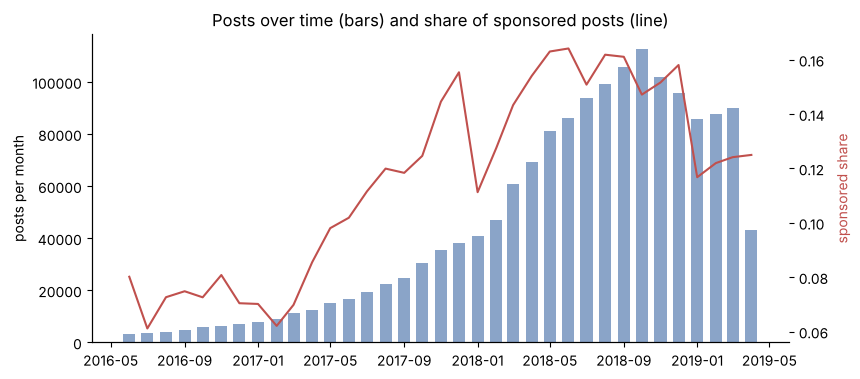

In [4]:
monthly = posts.set_index("ts").resample("MS").agg({"post_id": "size", "sponsored": "mean"})
monthly = monthly.loc["2016-06":"2019-04"]
fig, ax = plt.subplots()
ax.bar(monthly.index, monthly.post_id, width=20, color="#8aa4c8")
ax.set_ylabel("posts per month")
ax2 = ax.twinx(); ax2.plot(monthly.index, monthly.sponsored, color="#c0504d"); ax2.set_ylabel("sponsored share", color="#c0504d")
ax.set_title("Posts over time (bars) and share of sponsored posts (line)");

Almost everything is from 2017–2019 and the collection ends in April–May 2019 (the last month is incomplete).
This defines our **temporal split** later: we learn from the past and evaluate on later months,
exactly like a real system that only knows the past when it makes a recommendation.

## 3. Likes mostly measure audience size

> **Term — log scale:** likes range from tens to millions. On a log scale, going from 1,000 to 2,000
> is the same step as from 100,000 to 200,000, so we compare *relative* differences.

correlation (log-log): 0.837


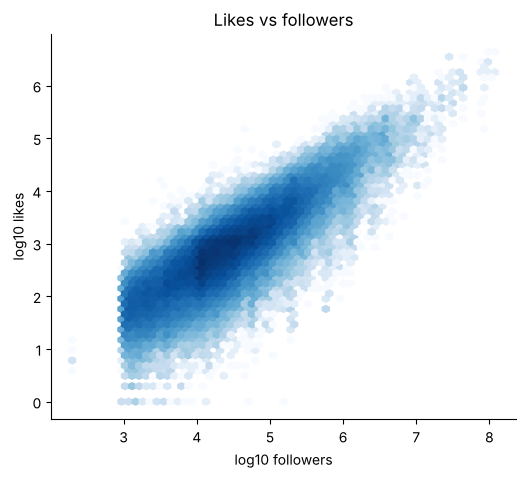

In [5]:
c = posts.merge(creators[["creator_id", "followers"]], on="creator_id", how="left").dropna(subset=["followers"])
c = c[(c.followers > 0) & (c.likes > 0)].sample(200_000, random_state=0)
fig, ax = plt.subplots(figsize=(6, 5))
ax.hexbin(np.log10(c.followers), np.log10(c.likes), gridsize=60, bins="log", cmap="Blues")
ax.set_xlabel("log10 followers"); ax.set_ylabel("log10 likes"); ax.set_title("Likes vs followers")
print("correlation (log-log):", round(np.corrcoef(np.log1p(c.followers), np.log1p(c.likes))[0, 1], 3))

A correlation of ~0.84 means raw likes are mostly *“how big is the account”*. Comparing a post's likes across
creators would just rank big accounts first. So we measure **relative engagement** instead: a post's
log-likes minus the median of that creator's **previous** 20 posts.

> **Term — data leakage:** using information that would not be available at prediction time.
> If a post's own likes were part of its baseline, the measure would partly “see itself”.
> That is why the baseline uses only *previous* posts (`shift(1)` in `data.py`).

,count,mean,50%,std
sponsored,,,,
organic,"1,226,277.000",0.051,0.029,0.479
sponsored,"198,231.000",-0.015,-0.015,0.489


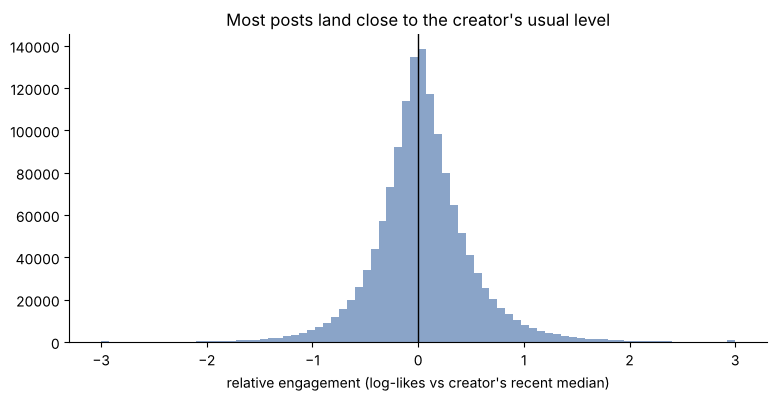

In [6]:
r = posts.dropna(subset=["rel_eng"])
fig, ax = plt.subplots()
ax.hist(r.rel_eng.clip(-3, 3), bins=80, color="#8aa4c8")
ax.axvline(0, color="k", lw=1); ax.set_xlabel("relative engagement (log-likes vs creator's recent median)")
ax.set_title("Most posts land close to the creator's usual level")
r.groupby("sponsored").rel_eng.describe()[["count", "mean", "50%", "std"]].rename(index={0: "organic", 1: "sponsored"})

Sponsored and organic posts perform almost the same relative to the creator's own norm.
Earlier we also tested predicting relative engagement from metadata only (posting time, caption length,
hashtag count, carousel, sponsored): it picked the better of two posts **50.7%** of the time — a coin flip.
That is why the project does **not** try to predict post performance from metadata.

## 4. The *sponsored* label is essentially a disclosure hashtag

> **Term — label:** the “correct answer” a supervised model learns to predict.

In [7]:
pd.crosstab(posts.sponsored.map({0: "organic", 1: "sponsored"}),
            posts.has_disclosure_tag.map({0: "no #ad-style tag", 1: "has #ad-style tag"}), normalize="index")

has_disclosure_tag,has #ad-style tag,no #ad-style tag
sponsored,,
organic,0.035,0.965
sponsored,0.973,0.027


Almost every sponsored post carries a tag like `#ad` or `#sponsored`. A model that sees the caption would just
learn “look for #ad”, which is circular. A meaningful *undisclosed sponsorship* detector must first **remove**
these tags and learn from the remaining text and images. That is a side feature, not the core of the project.

## 5. The real asset: a brand–creator graph

Nearly every post mentions a brand, so the data forms a **bipartite graph**: brands on one side, creators on
the other, edges for organic mentions and paid collaborations (with timestamps).

> **Term — bipartite graph:** a network with two kinds of nodes where edges only connect different kinds
> (brand ↔ creator, never brand ↔ brand).

In [8]:
paid = inter[inter.sponsored == 1]
pairs = paid.drop_duplicates(["brand", "creator_id"])
per_brand = pairs.groupby("brand").size()
pd.Series({
    "brands with ≥1 paid collaboration": per_brand.size,
    "distinct paid brand–creator pairs": len(pairs),
    "median paid creators per brand": per_brand.median(),
    "90th percentile": per_brand.quantile(.9),
    "pairs that collaborated more than once": round((paid.groupby(["brand", "creator_id"]).size() >= 2).mean(), 3),
}).to_frame("value")

,value
brands with ≥1 paid collaboration,"16,980.000"
distinct paid brand–creator pairs,"149,677.000"
median paid creators per brand,3.000
90th percentile,18.000
pairs that collaborated more than once,0.284


**Does an organic mention come before the first paid collaboration?**

In [9]:
first_paid = paid.groupby(["brand", "creator_id"]).ts.min().rename("first_paid")
org = inter[inter.sponsored == 0].groupby(["brand", "creator_id"]).ts.min().rename("first_organic")
j = first_paid.to_frame().join(org, how="left")
share = (j.first_organic < j.first_paid).mean()
print(f"{share:.1%} of first paid collaborations were preceded by an organic mention of the same brand")

17.9% of first paid collaborations were preceded by an organic mention of the same brand


Almost one in five. Given tens of thousands of possible creators per brand, this is a strong signal: creators who already talk
about a brand often become its paid partners. It motivates the **organic mentions** baseline in notebook 02.

## 6. Niches: fitness, beauty, food…?

Instagram's profile category is not a content niche: most creators are simply *“Creators & Celebrities”*.

In [10]:
cat = creators.ig_category.replace({"": "(empty)", "NULL": "(empty)"}).value_counts(normalize=True).head(6)
cat.to_frame("share of creators")

,share of creators
ig_category,
Creators & Celebrities,0.642
(empty),0.158
Publishers,0.048
Personal Goods & General Merchandise Stores,0.040
General Interest,0.037
Non-Profits & Religious Organizations,0.015


So we **learn niches from hashtags** with a topic model.

> **Term — topic model / NMF:** each creator is treated as a “document” made of the hashtags they use.
> TF-IDF turns documents into numbers (frequent-everywhere tags get low weight, distinctive tags high weight).
> **Non-negative Matrix Factorization** then splits the creator × hashtag matrix into a small number of topics:
> each topic is a weighted list of hashtags, and each creator is a mix of topics. It is **unsupervised** —
> nobody tells it what “fitness” is; it finds tags that tend to appear together.

Two cleaning steps matter:
* generic tags (`#love`, `#instagood`) and disclosure tags (`#ad`) are removed;
* **brand campaign tags** (`#danielwellington`, `#fashionnovacurve`) are removed — otherwise the model learns
  *“creators who worked with Daniel Wellington”* as a topic, which is a brand deal, not a niche.

In [11]:
docs = N.creator_documents(posts, set(brands.brand))
sample = docs.sample(5000, random_state=0)
rows = []
for k in [6, 8, 10, 12, 15, 20]:
    vec, nmf, W = N.fit_nmf(docs, k)
    coh = N.npmi_coherence(sample, N.top_terms(vec, nmf))
    rows.append({"topics": k, "mean coherence": np.mean(coh), "worst topic": np.min(coh)})
pd.DataFrame(rows).set_index("topics")

,mean coherence,worst topic
topics,,
6,0.481,0.324
8,0.447,0.232
10,0.460,0.332
12,0.420,0.024
15,0.432,0.069
20,0.391,-0.017


> **Term — topic coherence (NPMI):** checks whether a topic's top hashtags really co-occur in the same creators.
> Ranges from −1 (never together) to 1 (always together). Higher = more interpretable.

There is no single “right” number of topics, and the metric alone does not decide. **6 topics** score slightly
higher on average, but they merge niches a brand would want separated (fashion with beauty, for example).
**10 topics** keep almost the same average coherence, have the **best worst-topic score** (no junk topic), and
separate the niches users care about. Above 12, a junk topic appears and niches split into near-duplicates
(e.g. two food topics). Choosing with both the number *and* human judgement is normal practice for topic models.

In [12]:
vec, nmf, W = N.fit_nmf(docs, 10)
tops = N.top_terms(vec, nmf, 10)
coh = N.npmi_coherence(sample, tops)
dominant = W.idxmax(axis=1)
pd.DataFrame({
    "niche": [N.NICHE_NAMES[i] for i in range(10)],
    "top hashtags": [" ".join(t[:8]) for t in tops],
    "coherence": coh,
    "share of creators": [(dominant == i).mean() for i in range(10)],
})

,niche,top hashtags,coherence,share of creators
0,general lifestyle,fashion style model beauty makeup hair smile ootd,0.344,0.182
1,food,feedfeed foodie foodblogger f52grams eeeeeats ...,0.526,0.092
2,fashion blogging,fashionblogger ootd styleblogger outfitoftheda...,0.467,0.095
3,beauty & makeup,makeup makeupartist mua beauty wakeupandmakeup...,0.493,0.090
4,parenting,momlife motherhood momblogger letthembelittle ...,0.624,0.080
5,fitness,fitness workout fitfam motivation fit gym fits...,0.513,0.076
6,travel,travel travelblogger wanderlust beautifuldesti...,0.438,0.099
7,shoppable fashion (LTK),ltkholidaystyle ltkswim ltkholidaywishlist nyf...,0.398,0.159
8,home & interior,interiordesign homedecor interior bhghome inte...,0.465,0.057
9,fast fashion & campaign tags,novababe soufeel soufeelgals soufeelnameneckla...,0.332,0.070


Names were assigned by reading the hashtags. Two topics are honest leftovers: *general lifestyle* (creators
without a clear niche) and *fast fashion & campaign tags* (campaign tags our filter did not catch, mixed with
plus-size fashion). Reporting this openly is better than pretending every topic is clean.

**Sanity check against a hand-written keyword dictionary** (`niches.KEYWORDS`): for creators whose hashtags
clearly match one keyword niche, does NMF agree?

In [13]:
kw = N.keyword_niches(docs)
clear = kw[kw.max(axis=1) >= 0.10]
kw_label = clear.idxmax(axis=1)
mapping = {"fashion": {2, 7}, "beauty": {3}, "fitness": {5}, "food": {1}, "travel": {6}, "family": {4}, "home": {8}}
agree = [dominant[c] in mapping[k] for c, k in kw_label.items()]
print(f"{len(clear):,} creators with a clear keyword niche; NMF agrees for {np.mean(agree):.1%} of them")
pd.crosstab(kw_label.rename("keyword niche"), dominant.loc[kw_label.index].map(N.NICHE_NAMES).rename("NMF niche"),
            normalize="index").round(2)

4,827 creators with a clear keyword niche; NMF agrees for 77.7% of them


NMF niche,beauty & makeup,fashion blogging,fast fashion & campaign tags,fitness,food,general lifestyle,home & interior,parenting,shoppable fashion (LTK),travel
keyword niche,,,,,,,,,,
beauty,0.860,0.010,0.030,0.000,0.000,0.080,0.010,0.000,0.000,0.000
family,0.000,0.010,0.000,0.000,0.010,0.030,0.010,0.920,0.010,0.020
fashion,0.020,0.560,0.070,0.010,0.000,0.220,0.010,0.010,0.080,0.010
fitness,0.000,0.000,0.010,0.980,0.010,0.000,0.000,0.000,0.000,0.000
food,0.010,0.000,0.000,0.020,0.960,0.000,0.010,0.000,0.000,0.000
home,0.000,0.000,0.000,0.000,0.000,0.020,0.980,0.000,0.000,0.000
travel,0.000,0.000,0.000,0.000,0.010,0.010,0.000,0.000,0.000,0.970


**Brands inherit a niche** from the creators who mention them: a brand mentioned mostly by fitness creators is a
fitness brand. This gives the “fitness companies, beauty companies” view without any manual labelling.

In [14]:
bn = N.brand_niches(inter, W, min_creators=10)
bn.columns = [N.NICHE_NAMES[i] for i in bn.columns]
strength = bn.max(axis=1)
top = (bn.idxmax(axis=1).to_frame("niche").assign(strength=strength)
       .join(per_brand.rename("paid creators")).fillna({"paid creators": 0}))
examples = (top[top.strength > 0.4].sort_values("paid creators", ascending=False)
            .groupby("niche").head(4).sort_values(["niche", "paid creators"], ascending=[True, False]))
examples

,niche,strength,paid creators
maybelline,beauty & makeup,0.431,294.000
nyxcosmetics,beauty & makeup,0.476,207.000
lorealmakeup,beauty & makeup,0.420,195.000
maccosmetics,beauty & makeup,0.403,192.000
krispclothing,fashion blogging,0.502,10.000
ootdmagazine,fashion blogging,0.439,8.000
kissinfashion,fashion blogging,0.436,6.000
dockersbygerli,fashion blogging,0.424,3.000
soufeeljewelry,fast fashion & campaign tags,0.426,242.000
rebelliousfashion,fast fashion & campaign tags,0.504,98.000


**Do brands collaborate inside their own niche?** Rows: brand niche. Columns: niche of the creators they paid.

same-niche collaborations: 41.9%


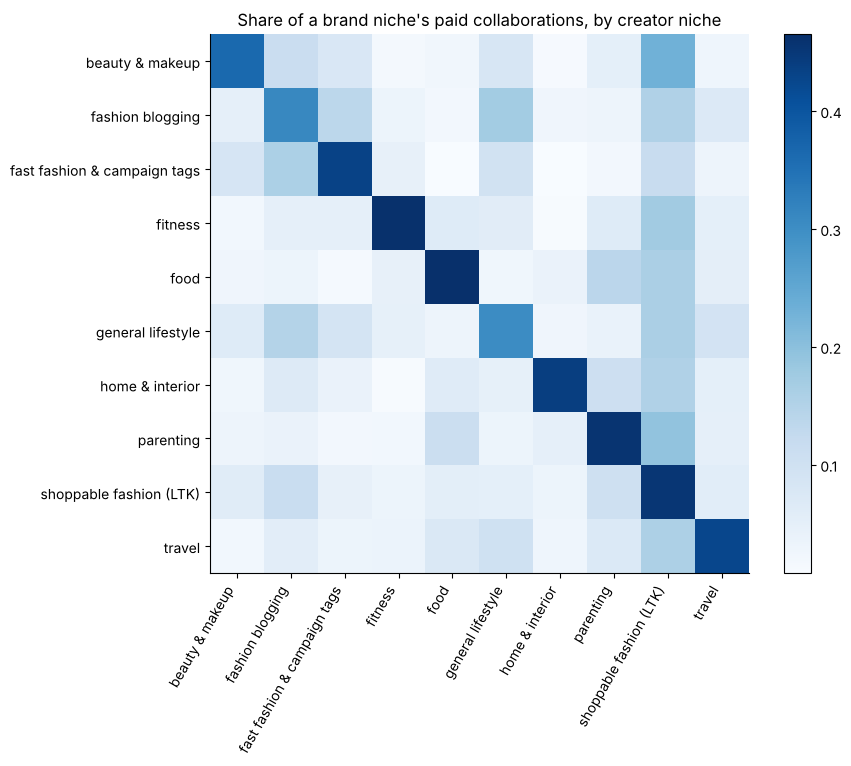

In [15]:
cn = W.idxmax(axis=1).map(N.NICHE_NAMES).rename("creator niche")
bnn = bn.idxmax(axis=1).rename("brand niche")
m = pairs.join(bnn, on="brand").join(cn, on="creator_id").dropna(subset=["brand niche", "creator niche"])
ct = pd.crosstab(m["brand niche"], m["creator niche"], normalize="index")
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(ct.values, cmap="Blues")
ax.set_xticks(range(len(ct.columns)), ct.columns, rotation=60, ha="right"); ax.set_yticks(range(len(ct.index)), ct.index)
ax.set_title("Share of a brand niche's paid collaborations, by creator niche"); plt.colorbar(im)
print(f"same-niche collaborations: {(m['brand niche'] == m['creator niche']).mean():.1%}")

## Takeaways

1. **Likes mostly measure audience size** (r ≈ 0.84), so performance must be measured relative to each creator.
2. **Post performance is not predictable from metadata** (≈ coin flip) → not a core goal.
3. **The sponsored label ≈ disclosure hashtag** → undisclosed-sponsorship detection only makes sense with those tags removed.
4. **The brand–creator graph is the real asset:** ~18% of first paid collaborations are preceded by an organic
   mention, and ~28% of paid pairs collaborate more than once. Same-niche collaborations are ~42%. → The core task becomes **recommending creators to brands**.
5. **Niches can be learned from hashtags** (10 topics, checked against a keyword dictionary) and transferred to
   brands. They become features for the ranker, explanations for users, and filters in the app.

Next: `02_baselines.ipynb` — simple recommenders and how we evaluate them.